In [ ]:
#  FMCG Sales Analytics

In [1]:
# ============ 0. SETUP, DATA INSPECTION & STANDARDISATION ============
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter

# ---- Professional colour palette (consistent across every chart) ----
C_BLUE, C_LBLUE, C_TEAL = "#1F4E79", "#5B9BD5", "#2A9D8F"      # primary / secondary / positive
C_GOLD, C_ORANGE, C_RED = "#F2B134", "#ED7D31", "#C0392B"      # caution / warning / negative
C_GREY, C_PURPLE        = "#7F8C9B", "#7D5BA6"                  # neutral / extra
PALETTE = [C_BLUE, C_TEAL, C_GOLD, C_ORANGE, C_LBLUE, C_PURPLE, C_GREY]

sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#E5E8EC", "axes.edgecolor": "#B0B7C3"})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40

FILE = "FMCG_EDA_1_to_4_Analysis_Results.xlsx"          # keep in the same folder as the notebook
df = pd.read_excel(FILE, sheet_name="Analysis_Fact")

print("Shape:", df.shape, "| Period:", df.Order_Date.min().date(), "→", df.Order_Date.max().date())
print("\nOrder status:\n", df.Order_Status.value_counts().to_string())
print("\nMissing values (columns used in this notebook):")
use_cols = ["Order_Date","Customer_ID","Quantity","Unit_Price","Discount_Pct","Payment_Method",
            "Recognized_Revenue","Recognized_Cost","Recognized_Profit"]
print(df[use_cols].isna().sum().to_string())

Shape: (606, 60) | Period: 2024-01-01 → 2024-12-31

Order status:
 Order_Status
Delivered     522
Cancelled      68
In Transit     12
Returned        3
Pending         1

Missing values (columns used in this notebook):
Order_Date             5
Customer_ID           40
Quantity              33
Unit_Price             7
Discount_Pct          39
Payment_Method        21
Recognized_Revenue     1
Recognized_Cost        0
Recognized_Profit      1


In [2]:
# ---- Standardise fields (no rows dropped here) ----
df["Product_Final"]  = df["Product_Name_Master"].fillna(df["Product_Name"])
df["Category_Final"] = df["Category_Master"].fillna(df["Category"])
df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")
df["Customer_ID"]    = df["Customer_ID"].fillna("Unknown")
df["Month"]          = df["Order_Date"].dt.to_period("M")

# Returned column is messy (0/1/'No'/'Yes'/'Y'/2/-1) -> clean binary; invalid codes become NaN
ret_map = {"0": 0, "no": 0, "1": 1, "yes": 1, "y": 1}
df["Return_Flag"] = df["Returned"].astype(str).str.strip().str.lower().map(ret_map)
df.loc[df["Order_Status"].eq("Returned"), "Return_Flag"] = 1
df["Is_Cancelled"] = df["Order_Status"].eq("Cancelled")

# ---- Data-integrity rules: a row failing any rule is NOT trusted for KPI analysis ----
EXCLUDE_9999_QTY = True      # 9999 looks like a system placeholder; set False if the business confirms these are real orders
exp_rev = df.Quantity * df.Unit_Price * (1 - df.Discount_Pct.fillna(0))
ratio   = df.Recognized_Revenue / exp_rev
df["Anomaly"] = np.select(
    [df.Quantity.eq(9999) & EXCLUDE_9999_QTY,
     (df.Quantity <= 0) | (df.Unit_Price <= 0),
     (ratio > 2) | ((ratio < 0.5) & (df.Recognized_Revenue > 0))],
    ["Placeholder quantity (9999)", "Non-positive quantity / price", "Revenue ≠ Qty × Price"],
    default="OK")

rec   = df[df.Is_Recognized == 1].copy()          # recognised revenue, as reported in EDA 1-4
clean = rec[rec.Anomaly == "OK"].copy()           # recognised AND passes integrity checks

print(f"Recognised rows: {len(rec)} | pass integrity checks: {len(clean)} | flagged: {len(rec)-len(clean)}")
print(f"Revenue as reported: {rec.Recognized_Revenue.sum():,.0f}  ->  after integrity filter: {clean.Recognized_Revenue.sum():,.0f}")

# ---- Reusable helpers ----
def kpi_table(data, by):
    t = (data.groupby(by, observed=True)
             .agg(Revenue=("Recognized_Revenue","sum"), Profit=("Recognized_Profit","sum"),
                  Orders=("Order_ID","nunique"), Units=("Recognized_Quantity","sum")).reset_index())
    t["Margin_%"]       = t.Profit / t.Revenue * 100
    t["AOV"]            = t.Revenue / t.Orders
    t["Revenue_Share_%"]= t.Revenue / t.Revenue.sum() * 100
    return t.sort_values("Revenue", ascending=False).reset_index(drop=True)

money = FuncFormatter(lambda x, _: f"{x:,.0f}")

def donut(ax, labels, values, title, colors=None):
    """Donut chart: share of total."""
    _, _, pct = ax.pie(values, labels=labels, autopct="%1.0f%%", startangle=90, pctdistance=0.79,
                       colors=colors or PALETTE, wedgeprops=dict(width=0.42, edgecolor="white"))
    for p in pct: p.set_color("white"); p.set_fontweight("bold"); p.set_fontsize(9)
    ax.set_title(title)

def label_bars(ax, fmt="%.1f"):
    """Print the value on top of every bar."""
    for cont in ax.containers: ax.bar_label(cont, fmt=fmt, padding=2, fontsize=9)
OVERALL_MARGIN = clean.Recognized_Profit.sum() / clean.Recognized_Revenue.sum() * 100
findings = []     # (EDA, finding, recommended action) -> printed in the executive summary at the end

Recognised rows: 450 | pass integrity checks: 442 | flagged: 8
Revenue as reported: 148,602  ->  after integrity filter: 97,411


In [3]:
# Sales Channel Performance

In [4]:
# ---- EDA 5 | ANALYSIS (tables only) ----
ch = kpi_table(clean, "Sales_Channel")
risk = (df.groupby("Sales_Channel")
          .agg(All_Orders=("Order_ID","nunique"),
               Cancel_Rate_pct=("Is_Cancelled", lambda s: s.mean()*100),
               Return_Rate_pct=("Return_Flag",  lambda s: s.mean()*100)).reset_index())
ch = ch.merge(risk, on="Sales_Channel")
display(ch.round(2))

top_rev, best_m, worst_m = ch.iloc[0], ch.loc[ch["Margin_%"].idxmax()], ch.loc[ch["Margin_%"].idxmin()]
worst_cancel = ch.loc[ch.Cancel_Rate_pct.idxmax()]
print(f"• Largest channel: {top_rev.Sales_Channel} ({top_rev['Revenue_Share_%']:.0f}% of revenue, margin {top_rev['Margin_%']:.1f}%).")
print(f"• Best margin: {best_m.Sales_Channel} ({best_m['Margin_%']:.1f}%) | Worst margin: {worst_m.Sales_Channel} ({worst_m['Margin_%']:.1f}%).")
print(f"• Highest cancellation rate: {worst_cancel.Sales_Channel} ({worst_cancel.Cancel_Rate_pct:.1f}%).")
findings.append(("5 Channel", f"{worst_m.Sales_Channel} earns {worst_m['Margin_%']:.1f}% margin vs {best_m.Sales_Channel} {best_m['Margin_%']:.1f}%.",
                 f"Review pricing/terms in {worst_m.Sales_Channel}; prioritise growth in {best_m.Sales_Channel}."))

,Sales_Channel,Revenue,Profit,Orders,Units,Margin_%,AOV,Revenue_Share_%,All_Orders,Cancel_Rate_pct,Return_Rate_pct
0,Modern Trade,"45,414.43","7,689.10",96,12654,16.93,473.07,46.62,127,13.28,4.69
1,Retail,"17,098.13","4,022.55",108,7782,23.53,158.32,17.55,159,10.00,8.86
2,Wholesale,"14,117.47","4,543.22",78,8444,32.18,180.99,14.49,104,10.48,2.86
3,Online,"13,680.36","3,672.09",83,11627,26.84,164.82,14.04,112,15.93,3.57
4,Distributor,"7,101.06","1,949.18",74,5362,27.45,95.96,7.29,98,6.00,7.07


• Largest channel: Modern Trade (47% of revenue, margin 16.9%).
• Best margin: Wholesale (32.2%) | Worst margin: Modern Trade (16.9%).
• Highest cancellation rate: Online (15.9%).


In [5]:
# Channel size and profit (donut + grouped bar)

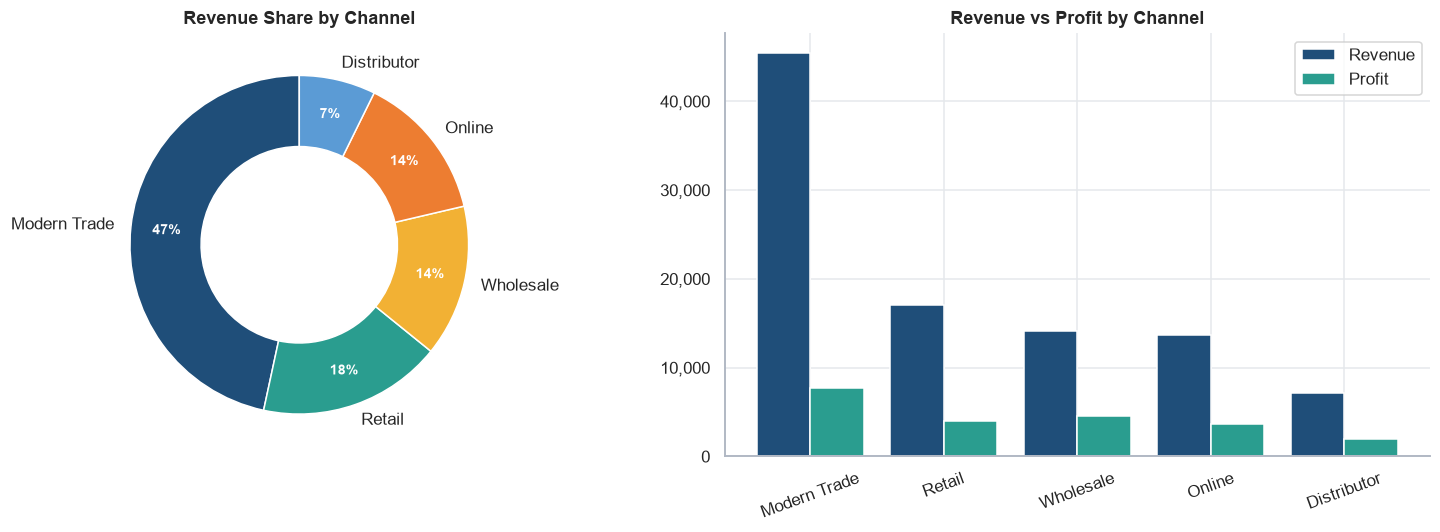

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
donut(ax[0], ch.Sales_Channel, ch.Revenue, "Revenue Share by Channel")
x, w = np.arange(len(ch)), 0.4
ax[1].bar(x - w/2, ch.Revenue, w, label="Revenue", color=C_BLUE)
ax[1].bar(x + w/2, ch.Profit,  w, label="Profit",  color=C_TEAL)
ax[1].set_xticks(x); ax[1].set_xticklabels(ch.Sales_Channel, rotation=20); ax[1].yaxis.set_major_formatter(money)
ax[1].set_title("Revenue vs Profit by Channel"); ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# Channel quality (margin + order loss)

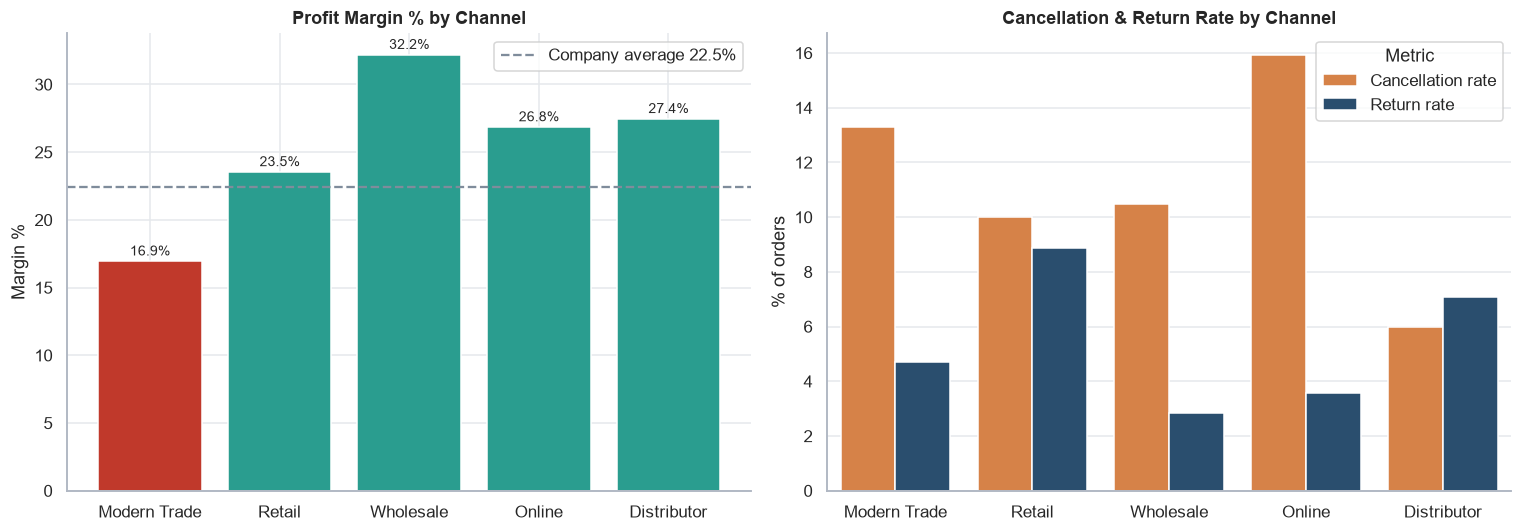

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colors = [C_RED if m < OVERALL_MARGIN else C_TEAL for m in ch["Margin_%"]]
ax[0].bar(ch.Sales_Channel, ch["Margin_%"], color=colors); label_bars(ax[0], "%.1f%%")
ax[0].axhline(OVERALL_MARGIN, ls="--", c=C_GREY, label=f"Company average {OVERALL_MARGIN:.1f}%")
ax[0].set_title("Profit Margin % by Channel"); ax[0].set_ylabel("Margin %"); ax[0].legend()

t = ch.melt(id_vars="Sales_Channel", value_vars=["Cancel_Rate_pct","Return_Rate_pct"], var_name="Metric", value_name="Rate_%")
t["Metric"] = t.Metric.map({"Cancel_Rate_pct": "Cancellation rate", "Return_Rate_pct": "Return rate"})
sns.barplot(data=t, x="Sales_Channel", y="Rate_%", hue="Metric", palette=[C_ORANGE, C_BLUE], ax=ax[1])
ax[1].set_title("Cancellation & Return Rate by Channel"); ax[1].set_xlabel(""); ax[1].set_ylabel("% of orders")
plt.tight_layout(); plt.show()

In [9]:
# Channel strategy map (bubble chart)

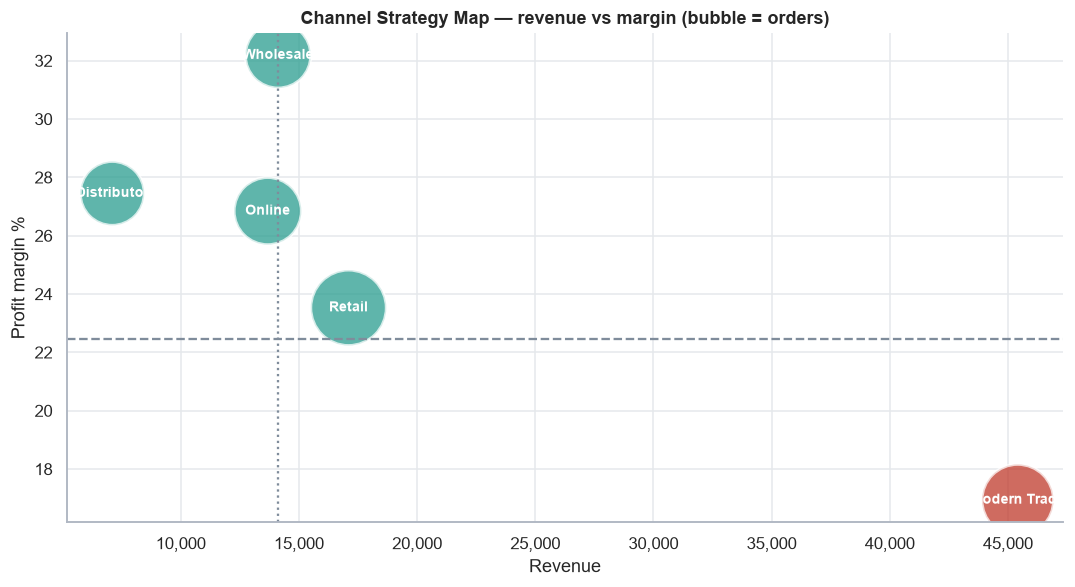

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [C_RED if m < OVERALL_MARGIN else C_TEAL for m in ch["Margin_%"]]
ax.scatter(ch.Revenue, ch["Margin_%"], s=ch.Orders / ch.Orders.max() * 2200 + 250, c=colors, alpha=.75, edgecolor="white", lw=2)
for _, r in ch.iterrows(): ax.annotate(r.Sales_Channel, (r.Revenue, r["Margin_%"]), ha="center", va="center", fontsize=9, fontweight="bold", color="white")
ax.axhline(OVERALL_MARGIN, ls="--", c=C_GREY); ax.axvline(ch.Revenue.median(), ls=":", c=C_GREY)
ax.set_xlabel("Revenue"); ax.set_ylabel("Profit margin %"); ax.xaxis.set_major_formatter(money)
ax.set_title("Channel Strategy Map — revenue vs margin (bubble = orders)")
plt.tight_layout(); plt.show()

In [11]:
# Margin % by Channel × Category (heatmap)

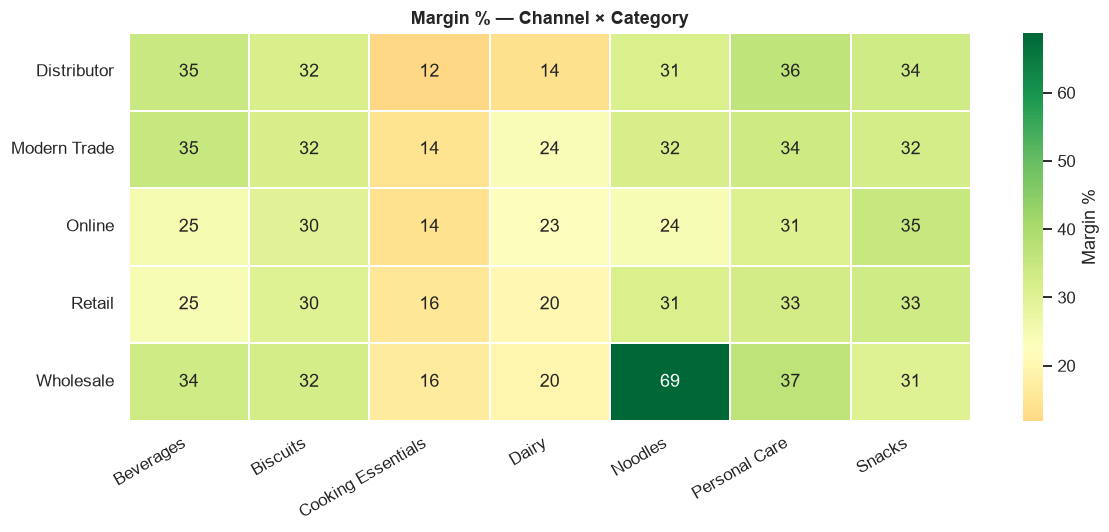

In [12]:
hm = clean.pivot_table(index="Sales_Channel", columns="Category_Final", values=["Recognized_Profit","Recognized_Revenue"], aggfunc="sum")
hm = hm["Recognized_Profit"] / hm["Recognized_Revenue"] * 100
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="RdYlGn", center=OVERALL_MARGIN, ax=ax, linewidths=1, linecolor="white", cbar_kws={"label": "Margin %"})
ax.set_title("Margin % — Channel × Category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

In [13]:
# Pricing & Discount Impact

In [14]:
# ---- EDA 6 | ANALYSIS (tables only) ----
d6 = clean.dropna(subset=["Discount_Pct", "Quantity"]).copy()
d6["Disc_Band"] = pd.Categorical((d6.Discount_Pct*100).round().astype(int).astype(str) + "%",
                                 categories=["0%","2%","5%","10%","15%"], ordered=True)
d6["Line_Margin_%"]  = d6.Recognized_Profit / d6.Recognized_Revenue.replace(0, np.nan) * 100
d6["Qty_Index"]      = d6.Quantity / d6.groupby("Product_Final").Quantity.transform("median")
d6["Discount_Value"] = d6.Quantity * d6.Unit_Price * d6.Discount_Pct
d6["Below_Cost"]     = d6.Unit_Price * (1 - d6.Discount_Pct) < d6.Unit_Cost

band = (d6.groupby("Disc_Band", observed=True)
          .agg(Lines=("Order_ID","count"), Revenue=("Recognized_Revenue","sum"), Profit=("Recognized_Profit","sum"),
               Discount_Given=("Discount_Value","sum"), Median_Qty_Index=("Qty_Index","median"),
               Below_Cost_Lines=("Below_Cost","sum")).reset_index())
band["Margin_%"] = band.Profit / band.Revenue * 100
display(band.round(2))

sp_margin = d6.Discount_Pct.rank().corr(d6["Line_Margin_%"].rank())
sp_volume = d6.Discount_Pct.rank().corr(d6.Qty_Index.rank())
print(f"Spearman correlation: discount vs margin = {sp_margin:+.2f} | discount vs volume lift = {sp_volume:+.2f}")

bc = d6[d6.Below_Cost]
print(f"Lines sold below unit cost after discount: {len(bc)} ({len(bc)/len(d6)*100:.1f}%)")
if len(bc): display(bc.groupby("Product_Final").agg(Lines=("Order_ID","count"), Profit_Lost=("Recognized_Profit","sum")).round(2))

b = band.set_index("Disc_Band")
m0, m15, q0, q15 = b.loc["0%","Margin_%"], b.loc["15%","Margin_%"], b.loc["0%","Median_Qty_Index"], b.loc["15%","Median_Qty_Index"]
print(f"• Margin falls from {m0:.1f}% (no discount) to {m15:.1f}% at 15%, while volume index moves {q0:.2f} → {q15:.2f}.")
print(f"• Total discount value given away: {d6.Discount_Value.sum():,.0f}.")
findings.append(("6 Discount", f"Margin {m0:.1f}% → {m15:.1f}% from 0% to 15% discount; volume index {q0:.2f} → {q15:.2f}; {len(bc)} below-cost lines.",
                 "Cap discounts where volume lift is weak; block below-cost net prices in order entry."))

,Disc_Band,Lines,Revenue,Profit,Discount_Given,Median_Qty_Index,Below_Cost_Lines,Margin_%
0,0%,130,"21,237.70","6,000.95",0.00,1.00,0,28.26
1,2%,76,"47,397.41","8,587.85",966.27,0.96,1,18.12
2,5%,95,"10,504.62","2,852.28",552.88,0.92,0,27.15
3,10%,68,"12,348.99","3,173.32","1,338.51",1.04,1,25.70
4,15%,43,"4,418.44",806.77,711.96,1.14,0,18.26


Spearman correlation: discount vs margin = -0.48 | discount vs volume lift = +0.04
Lines sold below unit cost after discount: 2 (0.5%)


,Lines,Profit_Lost
Product_Final,,
Cheddar Cheese 200G,1,-12.90
Energy Drink 250Ml,1,-7.20


• Margin falls from 28.3% (no discount) to 18.3% at 15%, while volume index moves 1.00 → 1.14.
• Total discount value given away: 3,570.


In [15]:
# Margin vs volume by discount band

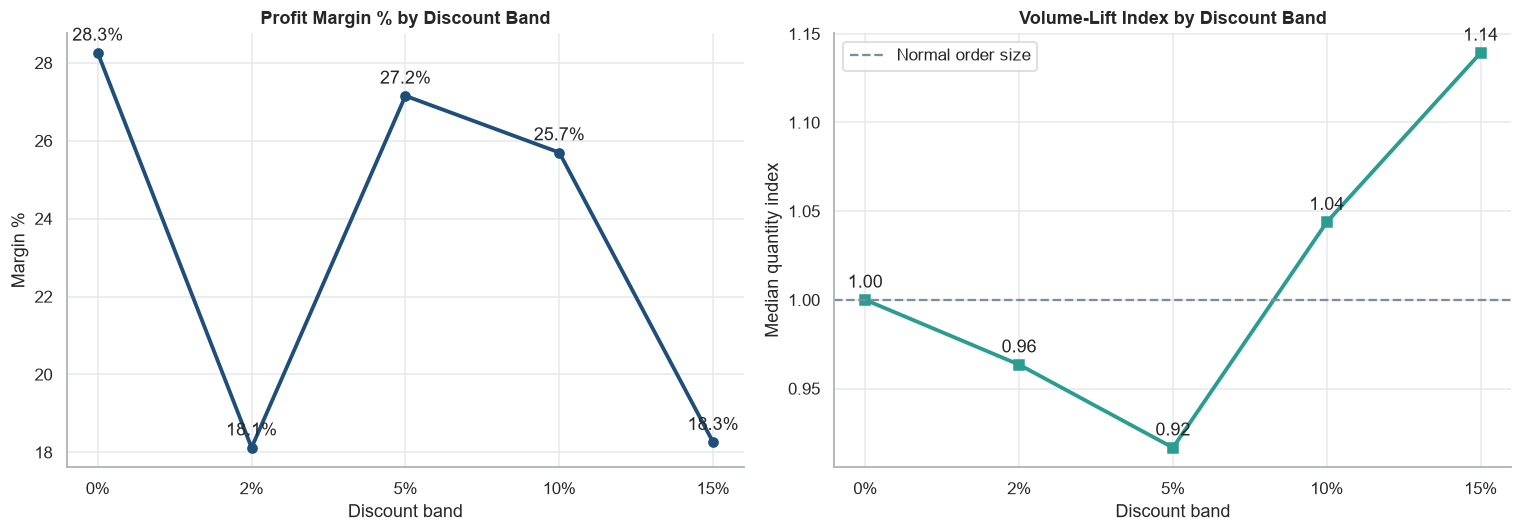

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(band.Disc_Band.astype(str), band["Margin_%"], marker="o", lw=2.5, color=C_BLUE)
for i, v in enumerate(band["Margin_%"]): ax[0].annotate(f"{v:.1f}%", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax[0].set_title("Profit Margin % by Discount Band"); ax[0].set_xlabel("Discount band"); ax[0].set_ylabel("Margin %")

ax[1].plot(band.Disc_Band.astype(str), band.Median_Qty_Index, marker="s", lw=2.5, color=C_TEAL)
ax[1].axhline(1, ls="--", c=C_GREY, label="Normal order size")
for i, v in enumerate(band.Median_Qty_Index): ax[1].annotate(f"{v:.2f}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax[1].set_title("Volume-Lift Index by Discount Band"); ax[1].set_xlabel("Discount band"); ax[1].set_ylabel("Median quantity index"); ax[1].legend()
plt.tight_layout(); plt.show()

In [17]:
# Margin stability and discount-margin relationship (box plot + regression scatter)

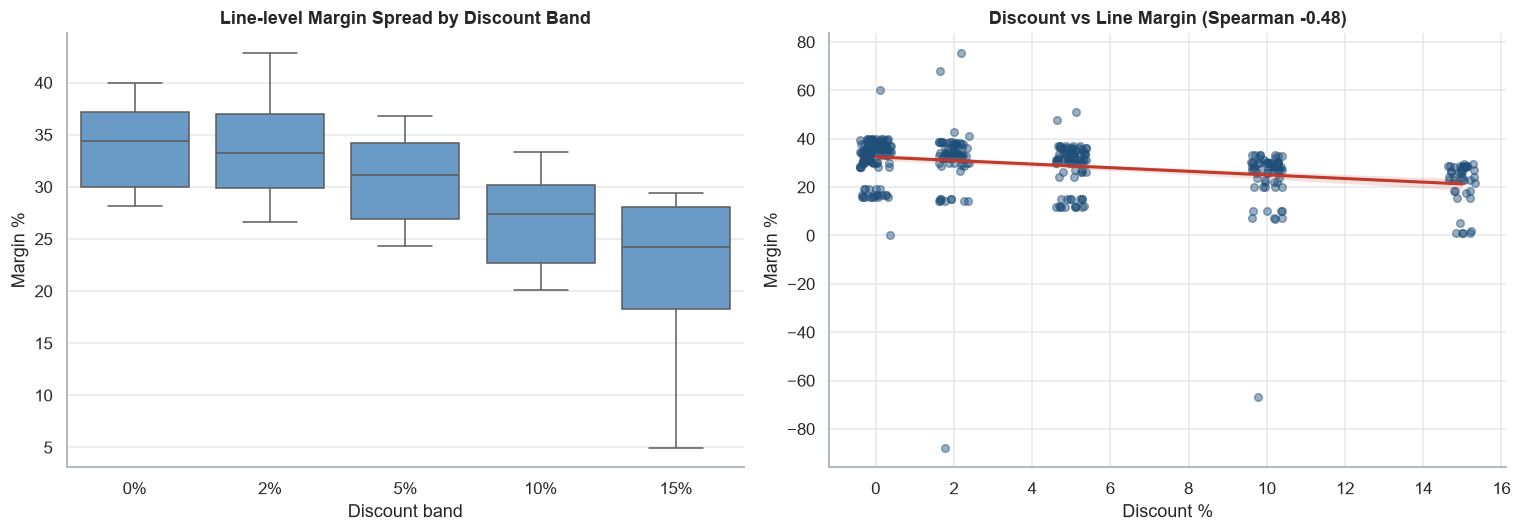

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=d6, x="Disc_Band", y="Line_Margin_%", color=C_LBLUE, showfliers=False, ax=ax[0])
ax[0].set_title("Line-level Margin Spread by Discount Band"); ax[0].set_xlabel("Discount band"); ax[0].set_ylabel("Margin %")

sns.regplot(data=d6.assign(Discount=d6.Discount_Pct * 100), x="Discount", y="Line_Margin_%", x_jitter=0.4, ax=ax[1],
            scatter_kws=dict(alpha=.45, s=25, color=C_BLUE), line_kws=dict(color=C_RED, lw=2))
ax[1].set_title(f"Discount vs Line Margin (Spearman {sp_margin:+.2f})"); ax[1].set_xlabel("Discount %"); ax[1].set_ylabel("Margin %")
plt.tight_layout(); plt.show()

In [19]:
# Cost of discounting (combo chart)

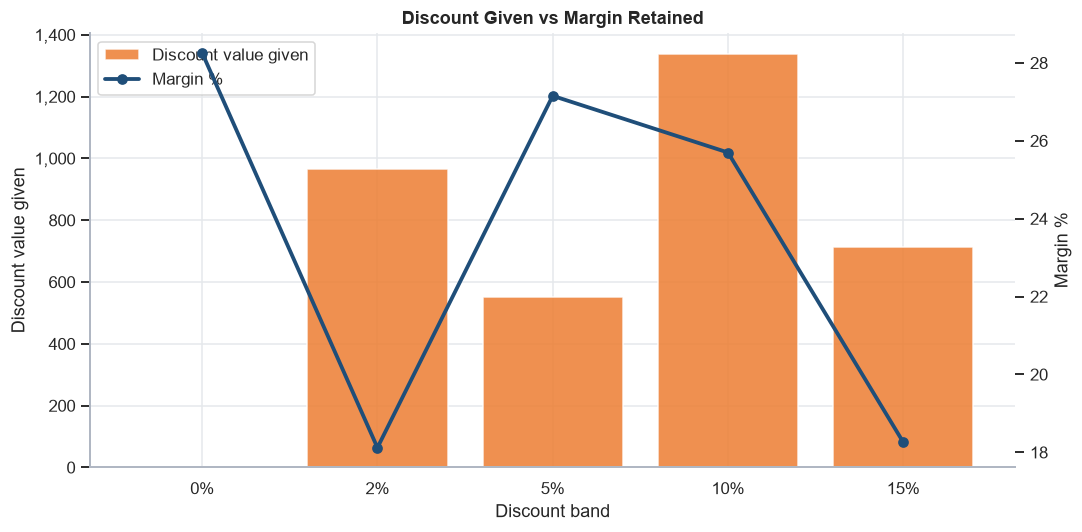

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(band.Disc_Band.astype(str), band.Discount_Given, color=C_ORANGE, alpha=.85, label="Discount value given")
ax.set_ylabel("Discount value given"); ax.yaxis.set_major_formatter(money); ax.set_xlabel("Discount band")
ax2 = ax.twinx(); ax2.plot(band.Disc_Band.astype(str), band["Margin_%"], marker="o", lw=2.5, color=C_BLUE, label="Margin %")
ax2.set_ylabel("Margin %"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title("Discount Given vs Margin Retained")
plt.tight_layout(); plt.show()

In [21]:
# Profitability & Loss Drivers

In [22]:
# ---- EDA 7 | ANALYSIS (tables only) ----
rev, cost, prof = clean.Recognized_Revenue.sum(), clean.Recognized_Cost.sum(), clean.Recognized_Profit.sum()
print(f"Revenue {rev:,.0f} | Cost {cost:,.0f} | Profit {prof:,.0f} | Margin {prof/rev*100:.1f}%")

cat   = kpi_table(clean, "Category_Final").sort_values("Margin_%", ascending=False)
brand = kpi_table(clean, "Brand").sort_values("Margin_%", ascending=False)
prod  = kpi_table(clean, "Product_Final")
prod["Margin_Quadrant"] = np.select(
    [(prod.Revenue >= prod.Revenue.median()) & (prod["Margin_%"] >= OVERALL_MARGIN),
     (prod.Revenue >= prod.Revenue.median()) & (prod["Margin_%"] <  OVERALL_MARGIN),
     (prod.Revenue <  prod.Revenue.median()) & (prod["Margin_%"] >= OVERALL_MARGIN)],
    ["Star", "Volume trap", "Niche earner"], default="Review / prune")
display(prod.groupby("Margin_Quadrant").agg(Products=("Product_Final","count"), Revenue=("Revenue","sum"), Profit=("Profit","sum")).round(0))
display(prod[["Product_Final","Revenue","Profit","Margin_%","Margin_Quadrant"]].round(1))

loss = clean[clean.Recognized_Profit < 0]
print(f"Loss-making lines: {len(loss)} | total loss {loss.Recognized_Profit.sum():,.1f}")
pc = clean.groupby("Product_Final").agg(List_Price=("Unit_Price","median"), Unit_Cost=("Unit_Cost","median"))
pc["List_Margin_%"] = (pc.List_Price - pc.Unit_Cost) / pc.List_Price * 100
print("Thinnest list-price margins:"); display(pc.sort_values("List_Margin_%").head(6).round(2))

rep = rec.groupby("Category_Final").apply(lambda g: g.Recognized_Profit.sum()/g.Recognized_Revenue.sum()*100).rename("Reported")
cln = clean.groupby("Category_Final").apply(lambda g: g.Recognized_Profit.sum()/g.Recognized_Revenue.sum()*100).rename("After_Cleaning")
cmp_ = pd.concat([rep, cln], axis=1); cmp_["Distortion_pts"] = cmp_.Reported - cmp_.After_Cleaning
print("Category margin % — reported vs after integrity filter:"); display(cmp_.sort_values("Distortion_pts").round(1))

worst, best = cat.iloc[-1], cat.iloc[0]
print(f"• Best category margin: {best.Category_Final} ({best['Margin_%']:.1f}%) | weakest: {worst.Category_Final} ({worst['Margin_%']:.1f}%).")
findings.append(("7 Profitability", f"Margins range {worst['Margin_%']:.1f}% ({worst.Category_Final}) to {best['Margin_%']:.1f}% ({best.Category_Final}); {len(loss)} loss-making lines.",
                 "Fix price/cost on thin-margin SKUs; shift promo spend to Star products; review 'Review / prune' SKUs."))

Revenue 97,411 | Cost 75,595 | Profit 21,876 | Margin 22.5%


,Products,Revenue,Profit
Margin_Quadrant,,,
Niche earner,11,"8,532.00","3,240.00"
Star,8,"31,754.00","10,257.00"
Volume trap,4,"57,125.00","8,380.00"


,Product_Final,Revenue,Profit,Margin_%,Margin_Quadrant
0,Basmati Rice 5Kg,"48,108.20","6,836.90",14.20,Volume trap
1,Shampoo 340Ml,"8,765.70","3,006.10",34.30,Star
2,Toothpaste 150G,"5,496.20","2,015.10",36.70,Star
3,Choco Cream Biscuits,"5,481.20","1,603.90",29.30,Star
4,Salted Peanuts 200G,"3,917.90","1,257.20",32.10,Star
5,Full Cream Milk 1L,"3,759.20",557.80,14.80,Volume trap
6,Cheddar Cheese 200G,"3,145.30",698.10,22.20,Volume trap
7,Digestive Biscuits,"2,990.90",981.70,32.80,Star
8,Soybean Oil 1L,"2,112.80",286.80,13.60,Volume trap
9,Orange Juice 1L,"1,927.90",441.70,22.90,Star


Loss-making lines: 2 | total loss -20.1
Thinnest list-price margins:


,List_Price,Unit_Cost,List_Margin_%
Product_Final,,,
Basmati Rice 5Kg,7.50,6.30,16.00
Soybean Oil 1L,2.40,2.00,16.67
Full Cream Milk 1L,1.30,1.05,19.23
Cheddar Cheese 200G,3.20,2.30,28.13
Cola 500Ml,0.60,0.42,30.00
Orange Juice 1L,1.80,1.25,30.56


Category margin % — reported vs after integrity filter:


,Reported,After_Cleaning,Distortion_pts
Category_Final,,,
Beverages,-157.00,30.10,-187.10
Snacks,28.20,33.60,-5.40
Noodles,36.00,40.60,-4.60
Biscuits,30.50,30.50,-0.10
Cooking Essentials,14.60,14.60,-0.00
Dairy,20.10,20.10,0.00
Personal Care,69.90,35.40,34.50


• Best category margin: Noodles (40.6%) | weakest: Cooking Essentials (14.6%).


In [23]:
# 

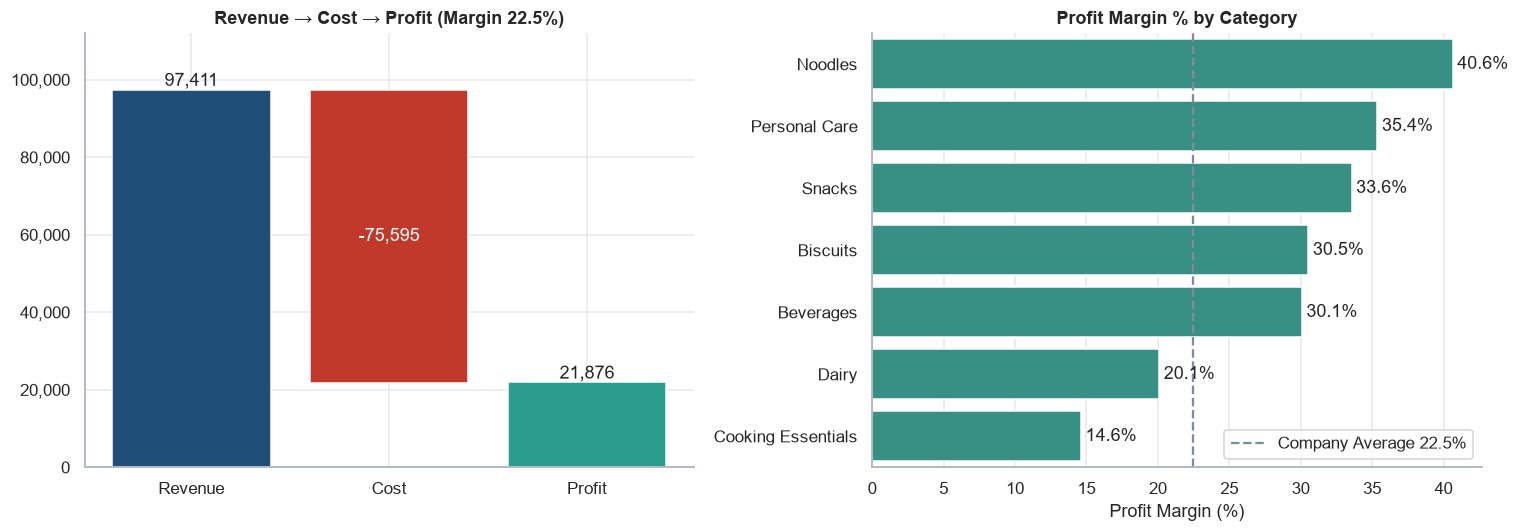

In [24]:

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Revenue, Cost and Profit
ax[0].bar(0, rev, color=C_BLUE)
ax[0].bar(1, -cost, bottom=rev, color=C_RED)
ax[0].bar(2, prof, color=C_TEAL)

# Value labels
ax[0].text(0, rev+1000, f"{rev:,.0f}", ha="center")
ax[0].text(1, rev-cost/2, f"-{cost:,.0f}", ha="center", va="center", color="white")
ax[0].text(2, prof+1000, f"{prof:,.0f}", ha="center")

ax[0].set_xticks([0, 1, 2], ["Revenue", "Cost", "Profit"])
ax[0].set_ylim(0, rev*1.15)
ax[0].yaxis.set_major_formatter(money)
ax[0].set_title(f"Revenue → Cost → Profit (Margin {prof/rev*100:.1f}%)")

# 2. Category Profit Margin
d = cat.sort_values("Margin_%", ascending=False)

sns.barplot(data=d, x="Margin_%", y="Category_Final", color=C_TEAL, ax=ax[1])

for container in ax[1].containers:
    ax[1].bar_label(container, fmt="%.1f%%", padding=3)

ax[1].axvline(OVERALL_MARGIN, color=C_GREY, ls="--",
              label=f"Company Average {OVERALL_MARGIN:.1f}%")

ax[1].set_title("Profit Margin % by Category")
ax[1].set_xlabel("Profit Margin (%)")
ax[1].set_ylabel("")
ax[1].legend()

plt.tight_layout()
plt.show()


In [25]:
# Brand margins (lollipop) and data-error distortion (dumbbell)

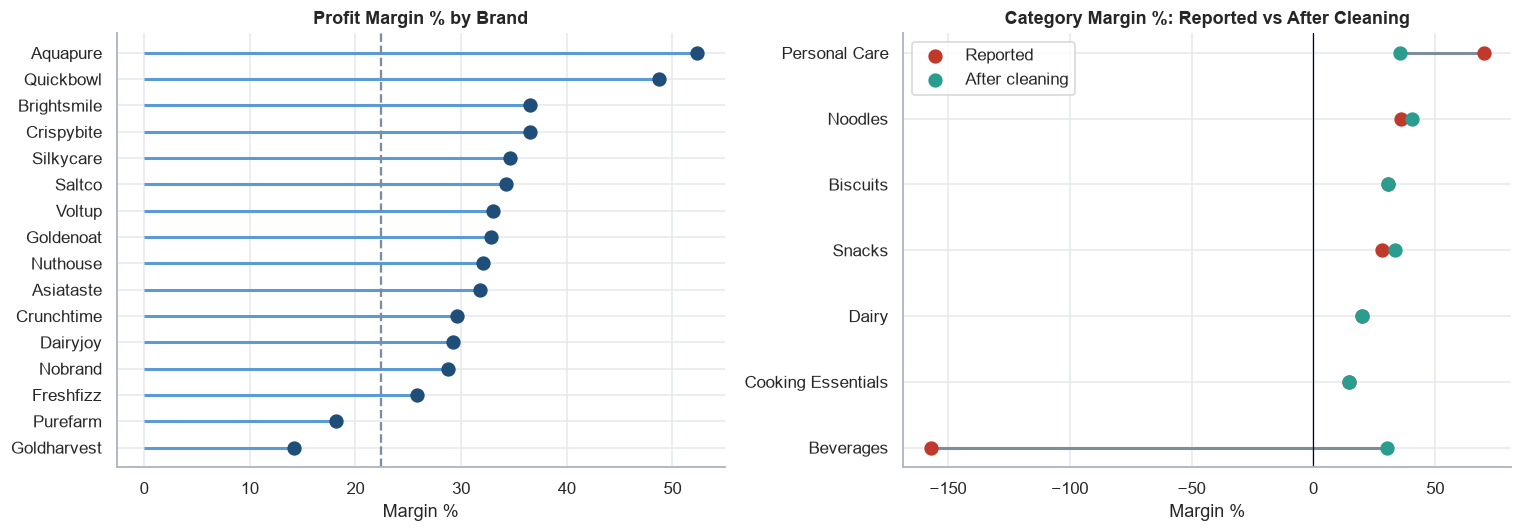

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
b = brand.sort_values("Margin_%")
ax[0].hlines(b.Brand, 0, b["Margin_%"], color=C_LBLUE, lw=2); ax[0].scatter(b["Margin_%"], b.Brand, color=C_BLUE, s=70, zorder=3)
ax[0].axvline(OVERALL_MARGIN, ls="--", c=C_GREY); ax[0].set_title("Profit Margin % by Brand"); ax[0].set_xlabel("Margin %")

d = cmp_.sort_values("Reported")
ax[1].hlines(d.index, d.After_Cleaning, d.Reported, color=C_GREY, lw=2)
ax[1].scatter(d.Reported, d.index, color=C_RED, s=70, zorder=3, label="Reported")
ax[1].scatter(d.After_Cleaning, d.index, color=C_TEAL, s=70, zorder=3, label="After cleaning")
ax[1].axvline(0, c="k", lw=.8); ax[1].set_title("Category Margin %: Reported vs After Cleaning"); ax[1].set_xlabel("Margin %"); ax[1].legend()
plt.tight_layout(); plt.show()

In [27]:
# Product map (bubble chart)

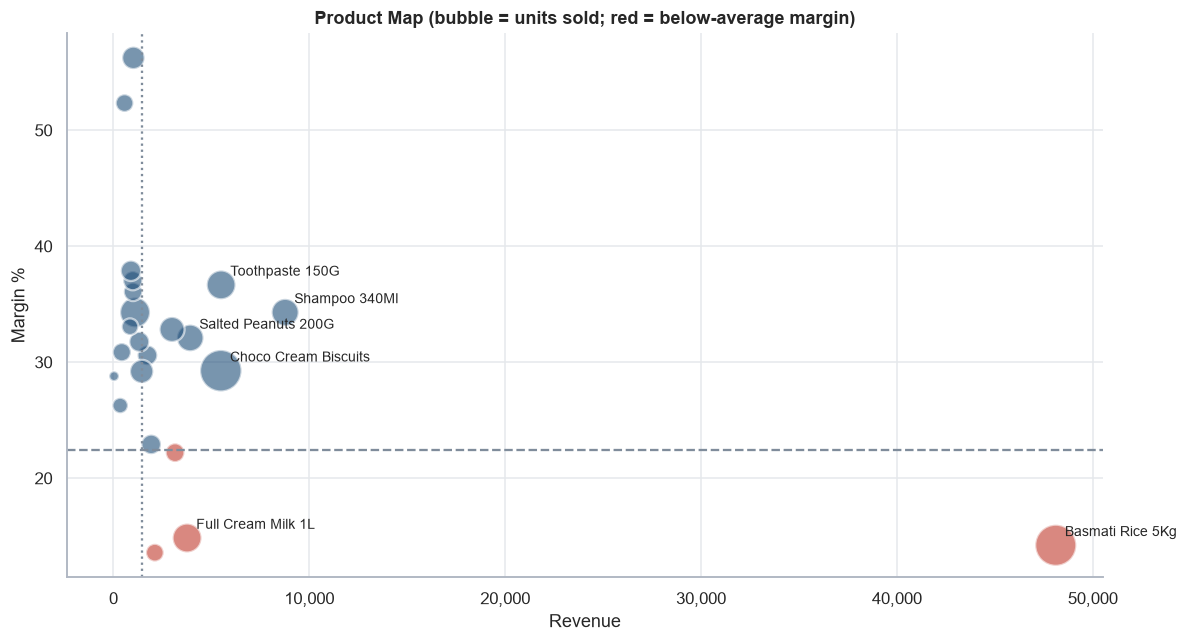

In [28]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(prod.Revenue, prod["Margin_%"], s=prod.Units / prod.Units.max() * 700 + 40,
           c=np.where(prod["Margin_%"] < OVERALL_MARGIN, C_RED, C_BLUE), alpha=.6, edgecolor="white", lw=1.5)
ax.axhline(OVERALL_MARGIN, ls="--", c=C_GREY); ax.axvline(prod.Revenue.median(), ls=":", c=C_GREY)
for _, r in prod.nlargest(6, "Revenue").iterrows(): ax.annotate(r.Product_Final, (r.Revenue, r["Margin_%"]), fontsize=9, xytext=(6, 6), textcoords="offset points")
ax.set_xlabel("Revenue"); ax.set_ylabel("Margin %"); ax.xaxis.set_major_formatter(money)
ax.set_title("Product Map (bubble = units sold; red = below-average margin)")
plt.tight_layout(); plt.show()

In [29]:
# Margin % by Region × Category (heatmap)

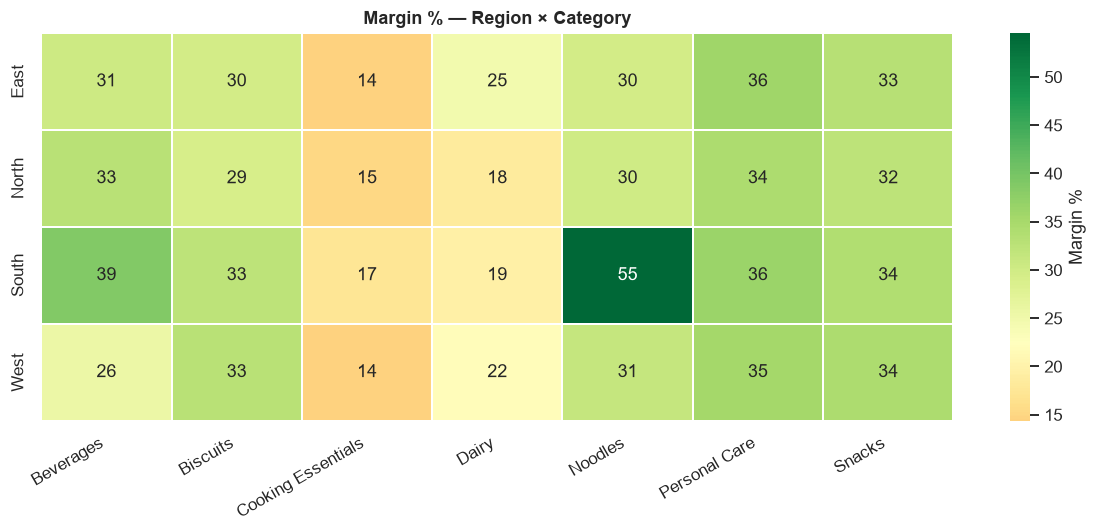

In [30]:
rc = clean.pivot_table(index="Region", columns="Category_Final", values=["Recognized_Profit","Recognized_Revenue"], aggfunc="sum")
rc = rc["Recognized_Profit"] / rc["Recognized_Revenue"] * 100
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(rc, annot=True, fmt=".0f", cmap="RdYlGn", center=OVERALL_MARGIN, ax=ax, linewidths=1, linecolor="white", cbar_kws={"label": "Margin %"})
ax.set_title("Margin % — Region × Category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

In [31]:
# Order Status, Returns & Cancellations

In [32]:
# ---- EDA 8 | ANALYSIS (tables only) ----
status = df.Order_Status.value_counts().rename_axis("Order_Status").reset_index(name="Orders")
status["Share_%"] = status.Orders / status.Orders.sum() * 100
display(status.round(1))

canc_val = df.loc[df.Is_Cancelled & (df.Anomaly == "OK"), "Sales_Amount_Final"].sum()
ret_val  = df.loc[(df.Return_Flag == 1) & (df.Anomaly == "OK"), "Sales_Amount_Final"].sum()
print(f"Cancellation rate: {df.Is_Cancelled.mean()*100:.1f}% | Return rate (valid flags): {df.Return_Flag.mean()*100:.1f}%")
print(f"Sales value cancelled: {canc_val:,.0f} | returned: {ret_val:,.0f}  (vs recognised {clean.Recognized_Revenue.sum():,.0f})")

def rate_table(col, min_n=10):
    t = (df.groupby(col).agg(Orders=("Order_ID","count"),
                             Cancel_Rate=("Is_Cancelled", lambda s: s.mean()*100),
                             Return_Rate=("Return_Flag",  lambda s: s.mean()*100)).reset_index())
    return t[t.Orders >= min_n].sort_values("Cancel_Rate", ascending=False)

def rate_plot(col, title, ax):                  # draws on the axis you give it
    t = rate_table(col).melt(id_vars=[col, "Orders"], value_vars=["Cancel_Rate","Return_Rate"], var_name="Metric", value_name="Rate_%")
    t["Metric"] = t.Metric.map({"Cancel_Rate": "Cancellation rate", "Return_Rate": "Return rate"})
    sns.barplot(data=t, x=col, y="Rate_%", hue="Metric", palette=[C_ORANGE, C_BLUE], ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("% of orders"); ax.tick_params(axis="x", rotation=25)

print("Highest return-rate products (≥15 orders):"); display(rate_table("Product_Final", 15).sort_values("Return_Rate", ascending=False).head(6).round(1))

from scipy.stats import chi2_contingency
p = chi2_contingency(pd.crosstab(df.Sales_Channel, df.Is_Cancelled))[1]
print(f"Chi-square p-value (channel vs cancellation) = {p:.3f} -> {'significant' if p < 0.05 else 'NOT statistically significant: treat gaps as directional'}")

wr, wc = rate_table("Region").iloc[0], rate_table("Sales_Channel").iloc[0]
print(f"• Highest cancellation: region {wr.Region} ({wr.Cancel_Rate:.1f}%), channel {wc.Sales_Channel} ({wc.Cancel_Rate:.1f}%).")
findings.append(("8 Cancel/Return", f"Cancellation {df.Is_Cancelled.mean()*100:.1f}% of orders (value {canc_val:,.0f}); worst channel {wc.Sales_Channel} {wc.Cancel_Rate:.1f}%, worst region {wr.Region} {wr.Cancel_Rate:.1f}%.",
                 "Investigate stock-outs/fulfilment in the worst channel & region; add reason codes for cancellations and returns."))

,Order_Status,Orders,Share_%
0,Delivered,522,86.10
1,Cancelled,68,11.20
2,In Transit,12,2.00
3,Returned,3,0.50
4,Pending,1,0.20


Cancellation rate: 11.2% | Return rate (valid flags): 5.6%
Sales value cancelled: 7,003 | returned: 2,284  (vs recognised 97,411)
Highest return-rate products (≥15 orders):


,Product_Final,Orders,Cancel_Rate,Return_Rate
9,Fruit Yogurt 150G,27,7.40,14.80
18,Salted Peanuts 200G,31,16.10,12.90
3,Cheddar Cheese 200G,27,14.80,11.10
16,Potato Chips 100G,20,15.00,10.50
11,Iodized Salt 1Kg,32,9.40,9.70
6,Cola 500Ml,21,9.50,9.50


Chi-square p-value (channel vs cancellation) = 0.192 -> NOT statistically significant: treat gaps as directional
• Highest cancellation: region South (13.4%), channel Online (15.9%).


In [33]:
# Order status mix (donut) and revenue at risk (bar)

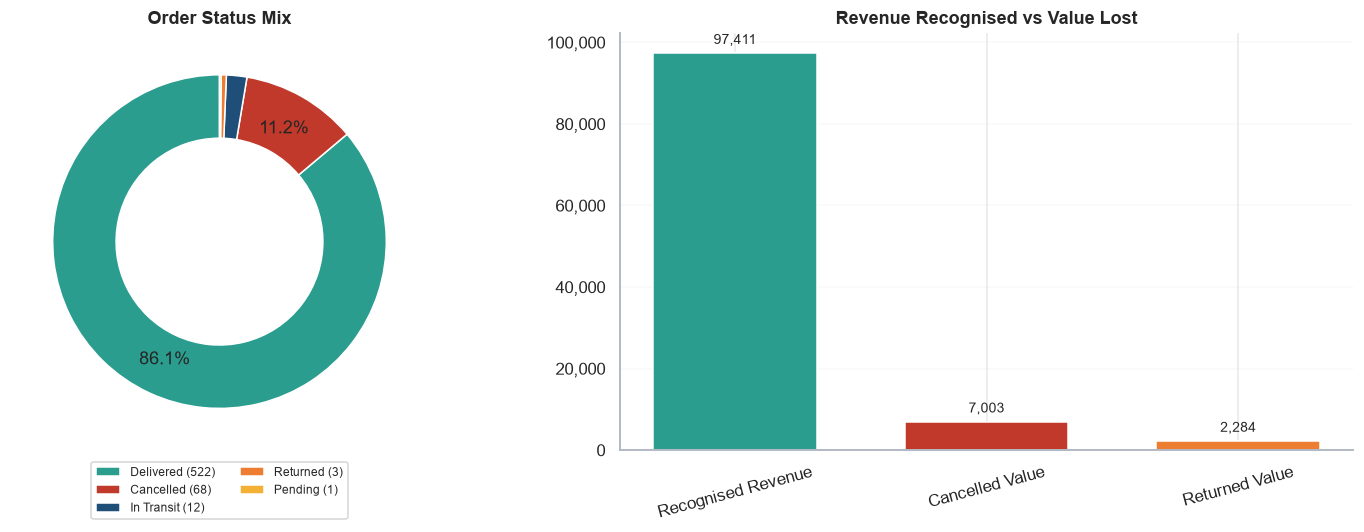

In [34]:

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Order Status Donut Chart
colors = {"Delivered": C_TEAL, "Cancelled": C_RED,
          "Returned": C_ORANGE, "Pending": C_GOLD,
          "In Transit": C_BLUE}

c = [colors.get(s, C_GREY) for s in status["Order_Status"]]

wedges, texts, autotexts = ax[0].pie(
    status["Orders"],
    colors=c,
    startangle=90,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    pctdistance=0.78,
    wedgeprops=dict(width=0.38, edgecolor="white")
)

# Add legend instead of overlapping labels
labels = [f"{s} ({v})" for s, v in
          zip(status["Order_Status"], status["Orders"])]

ax[0].legend(wedges, labels, loc="lower center",
             bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)

ax[0].set_title("Order Status Mix", fontweight="bold")


# 2. Revenue Recognised vs Value Lost
vals = pd.Series({
    "Recognised Revenue": clean["Recognized_Revenue"].sum(),
    "Cancelled Value": canc_val,
    "Returned Value": ret_val
})

bars = ax[1].bar(
    vals.index, vals.values,
    color=[C_TEAL, C_RED, C_ORANGE], width=0.65
)

ax[1].bar_label(bars, labels=[f"{v:,.0f}" for v in vals],
                padding=4, fontsize=9)

ax[1].set_title("Revenue Recognised vs Value Lost", fontweight="bold")
ax[1].yaxis.set_major_formatter(money)
ax[1].tick_params(axis="x", rotation=15)
ax[1].grid(axis="y", alpha=0.25)
ax[1].set_axisbelow(True)

plt.tight_layout()
plt.show()


In [35]:
 # Cancellations and returns by region and by channel

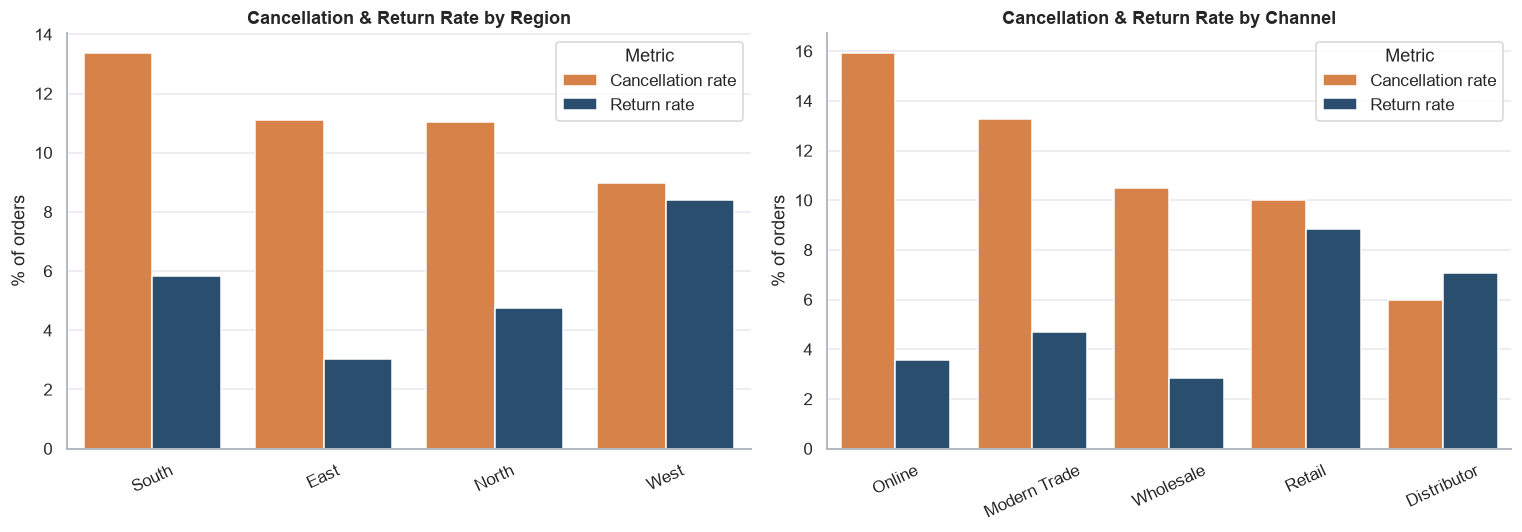

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rate_plot("Region", "Cancellation & Return Rate by Region", ax[0])
rate_plot("Sales_Channel", "Cancellation & Return Rate by Channel", ax[1])
plt.tight_layout(); plt.show()


In [37]:
# Cancellations and returns by category and by payment method

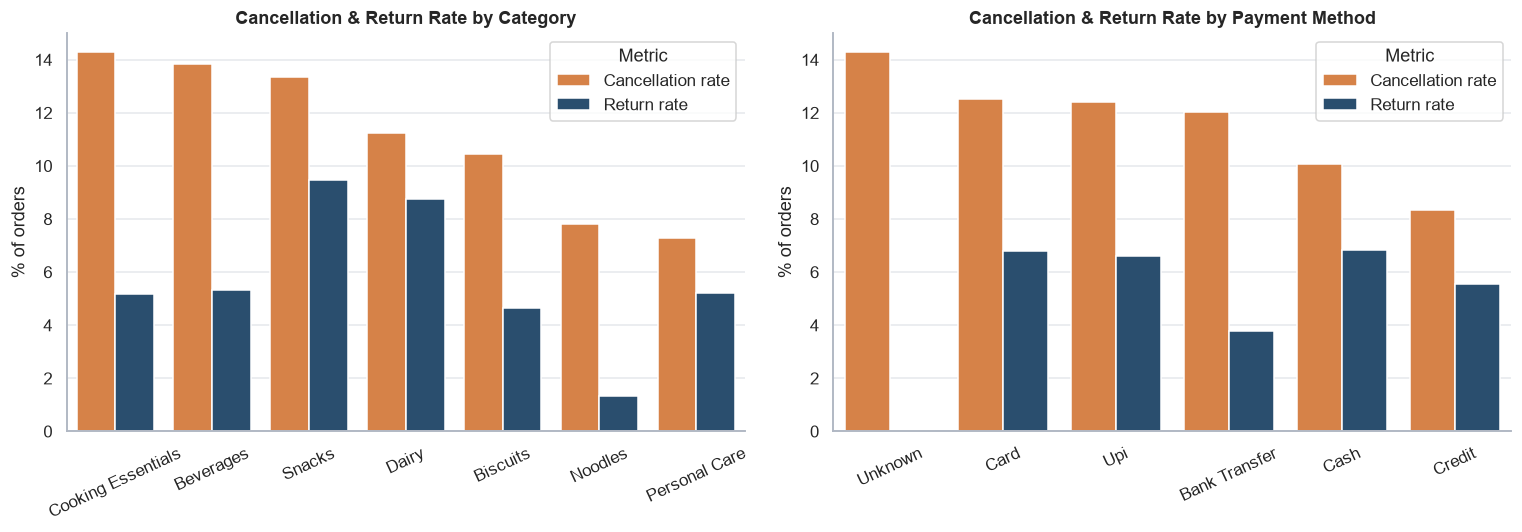

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rate_plot("Category_Final", "Cancellation & Return Rate by Category", ax[0])
rate_plot("Payment_Method", "Cancellation & Return Rate by Payment Method", ax[1])
plt.tight_layout(); plt.show()

In [39]:
# Monthly order outcomes (stacked bar) and cancellation trend (line)

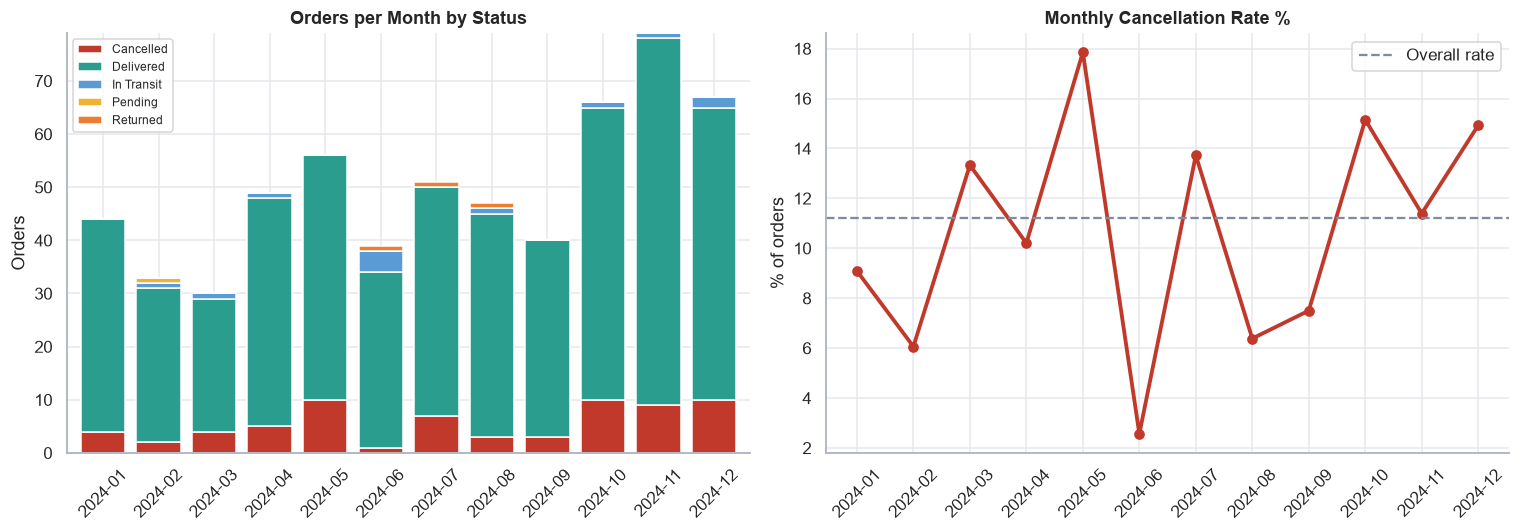

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
st_colors = {"Delivered": C_TEAL, "Cancelled": C_RED, "Returned": C_ORANGE, "Pending": C_GOLD, "In Transit": C_LBLUE}
ms = pd.crosstab(df.Month.astype(str), df.Order_Status)
ms.plot(kind="bar", stacked=True, ax=ax[0], color=[st_colors.get(c, C_GREY) for c in ms.columns], width=.8)
ax[0].set_title("Orders per Month by Status"); ax[0].set_xlabel(""); ax[0].set_ylabel("Orders"); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(title="", fontsize=8)

mc = df.groupby("Month").Is_Cancelled.mean().mul(100); mc.index = mc.index.astype(str)
ax[1].plot(mc.index, mc.values, marker="o", lw=2.5, color=C_RED); ax[1].axhline(df.Is_Cancelled.mean()*100, ls="--", c=C_GREY, label="Overall rate")
ax[1].set_title("Monthly Cancellation Rate %"); ax[1].set_ylabel("% of orders"); ax[1].tick_params(axis="x", rotation=45); ax[1].legend()
plt.tight_layout(); plt.show()

In [41]:
# Cancellation % by Region × Channel (heatmap)

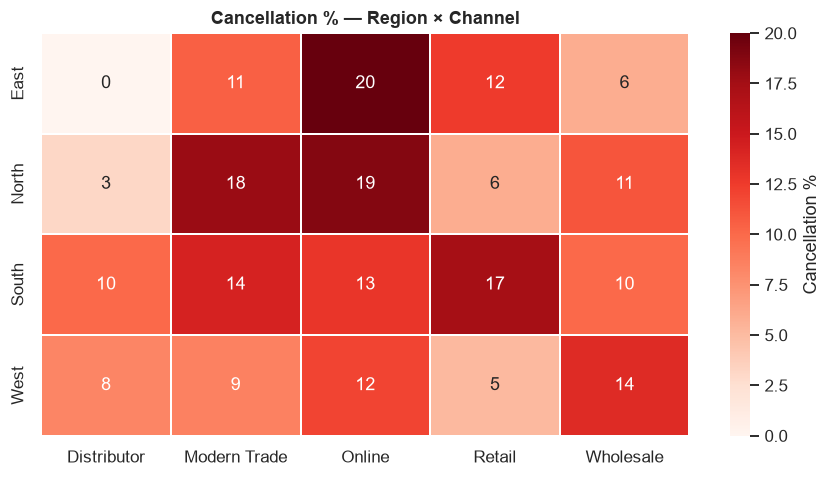

In [42]:
hmx = df.pivot_table(index="Region", columns="Sales_Channel", values="Is_Cancelled", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(hmx, annot=True, fmt=".0f", cmap="Reds", ax=ax, linewidths=1, linecolor="white", cbar_kws={"label": "Cancellation %"})
ax.set_title("Cancellation % — Region × Channel"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [43]:
# Pareto & ABC Analysis (Products and Customers)

In [44]:
# ---- EDA 9 | ANALYSIS (tables only) ----
def abc(data, key):
    t = data.groupby(key).agg(Revenue=("Recognized_Revenue","sum"), Profit=("Recognized_Profit","sum")).sort_values("Revenue", ascending=False).reset_index()
    t["Cum_Share_%"] = t.Revenue.cumsum() / t.Revenue.sum() * 100
    prev = t["Cum_Share_%"].shift(fill_value=0)                  # class decided by share BEFORE adding this item
    t["Class"] = np.select([prev < 80, prev < 95], ["A", "B"], default="C")
    t["Margin_%"] = t.Profit / t.Revenue * 100
    return t

def abc_summary(t):
    return (t.groupby("Class").agg(Items=("Revenue","count"), Revenue=("Revenue","sum"), Profit=("Profit","sum"))
              .assign(**{"Items_%": lambda x: x.Items/x.Items.sum()*100, "Revenue_%": lambda x: x.Revenue/x.Revenue.sum()*100,
                         "Margin_%": lambda x: x.Profit/x.Revenue*100}))

def pareto_plot(t, key, title, top=None):                        # ONE pareto chart per call
    s = t.head(top) if top else t
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.bar(range(len(s)), s.Revenue, color=s.Class.map({"A": C_TEAL, "B": C_GOLD, "C": C_RED}))
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s[key], rotation=70, ha="right", fontsize=9)
    ax.yaxis.set_major_formatter(money); ax.set_ylabel("Revenue")
    ax2 = ax.twinx(); ax2.plot(range(len(s)), s["Cum_Share_%"], c=C_BLUE, marker="o", ms=4, lw=1.5)
    ax2.axhline(80, ls="--", c=C_GREY); ax2.set_ylim(0, 105); ax2.set_ylabel("Cumulative revenue %"); ax2.grid(False)
    ax.set_title(title); plt.tight_layout(); plt.show()

pa = abc(clean, "Product_Final")
ca = abc(clean[clean.Customer_ID != "Unknown"], "Customer_ID")
print("PRODUCT ABC");  display(abc_summary(pa).round(1))
print("CUSTOMER ABC (known customers)"); display(abc_summary(ca).round(1))
print("A-class products:", ", ".join(pa[pa.Class == "A"].Product_Final))

n80_p  = int((pa["Cum_Share_%"].shift(fill_value=0) < 80).sum())
top20c = ca.head(max(1, round(len(ca)*0.2))).Revenue.sum() / ca.Revenue.sum() * 100
unk_share = clean.loc[clean.Customer_ID == "Unknown", "Recognized_Revenue"].sum() / clean.Recognized_Revenue.sum() * 100
print(f"• {n80_p} of {len(pa)} products ({n80_p/len(pa)*100:.0f}%) generate 80% of revenue.")
print(f"• Top 20% of customers ({max(1, round(len(ca)*0.2))}) generate {top20c:.0f}% of known-customer revenue. Revenue with no customer ID: {unk_share:.1f}%.")
findings.append(("9 ABC/Pareto", f"{n80_p} of {len(pa)} products = 80% of revenue; top 20% customers = {top20c:.0f}% of revenue; {unk_share:.1f}% of revenue has no customer ID.",
                 "Protect stock & margin of A-items; key-account plan for top customers; enforce customer ID at order entry."))

PRODUCT ABC


,Items,Revenue,Profit,Items_%,Revenue_%,Margin_%
Class,,,,,,
A,7,"78,673.70","15,975.10",30.40,80.80,20.30
B,9,"14,644.30","4,390.60",39.10,15.00,30.00
C,7,"4,093.40","1,510.40",30.40,4.20,36.90


CUSTOMER ABC (known customers)


,Items,Revenue,Profit,Items_%,Revenue_%,Margin_%
Class,,,,,,
A,16,"72,139.90","14,708.20",25.80,80.10,20.40
B,23,"13,707.40","3,655.10",37.10,15.20,26.70
C,23,"4,196.10","1,211.30",37.10,4.70,28.90


A-class products: Basmati Rice 5Kg, Shampoo 340Ml, Toothpaste 150G, Choco Cream Biscuits, Salted Peanuts 200G, Full Cream Milk 1L, Cheddar Cheese 200G
• 7 of 23 products (30%) generate 80% of revenue.
• Top 20% of customers (12) generate 75% of known-customer revenue. Revenue with no customer ID: 7.6%.


In [45]:
# Product Pareto chart

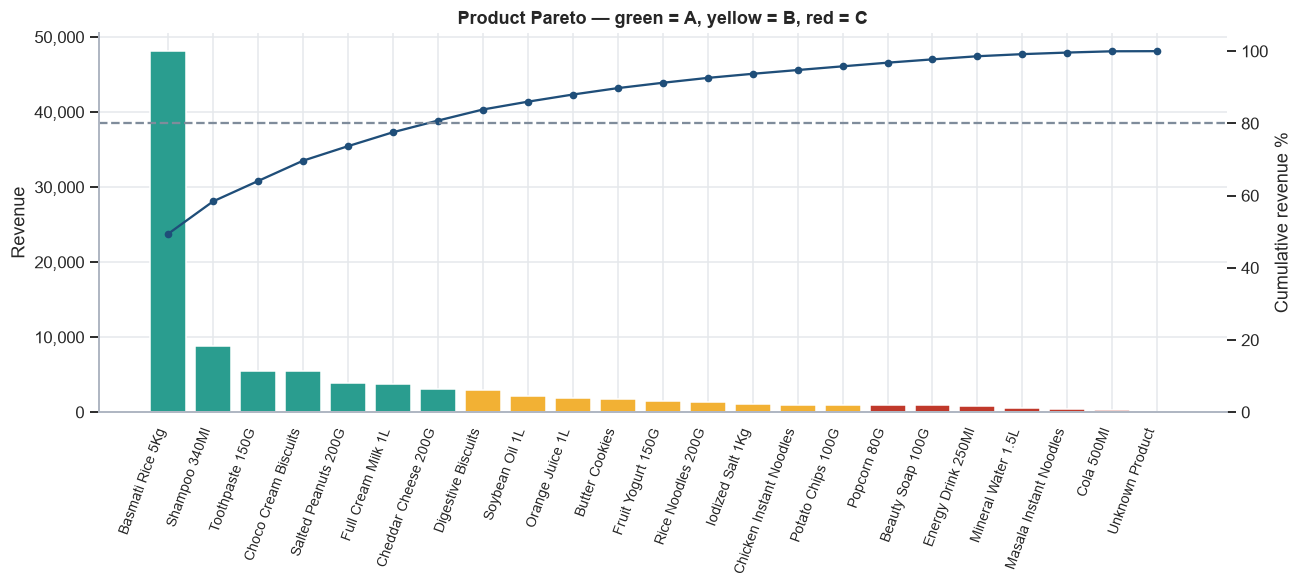

In [46]:
pareto_plot(pa, "Product_Final", "Product Pareto — green = A, yellow = B, red = C")

In [47]:
# Customer Pareto chart (top 30 customers)

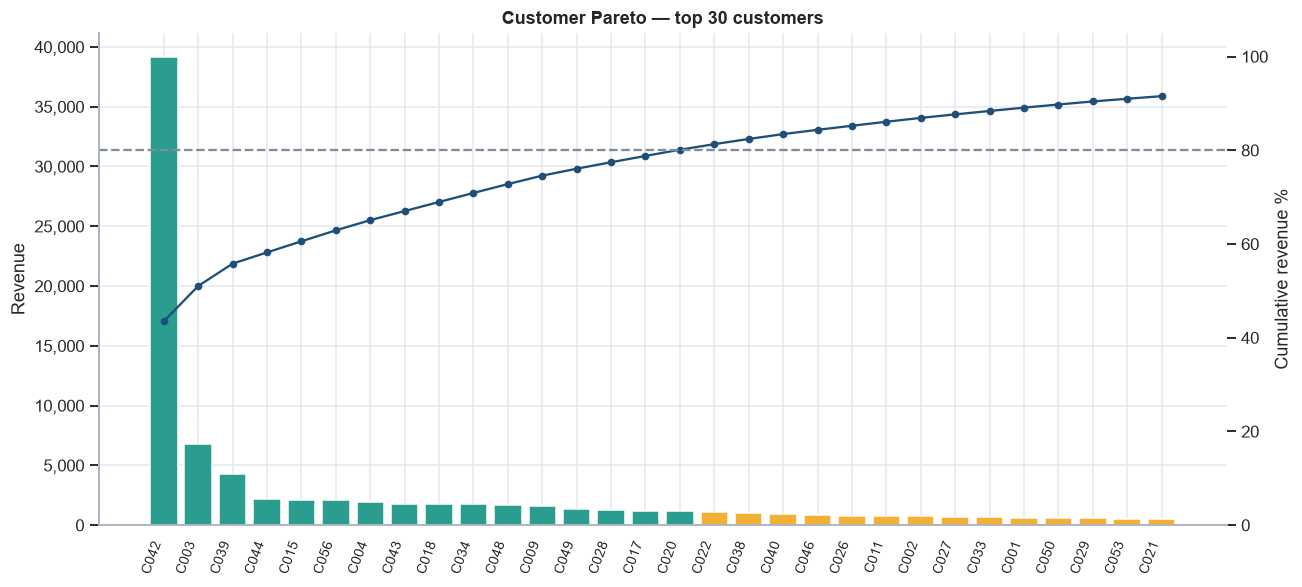

In [48]:
pareto_plot(ca, "Customer_ID", "Customer Pareto — top 30 customers", top=30)

In [49]:
# ABC concentration and profitability by class

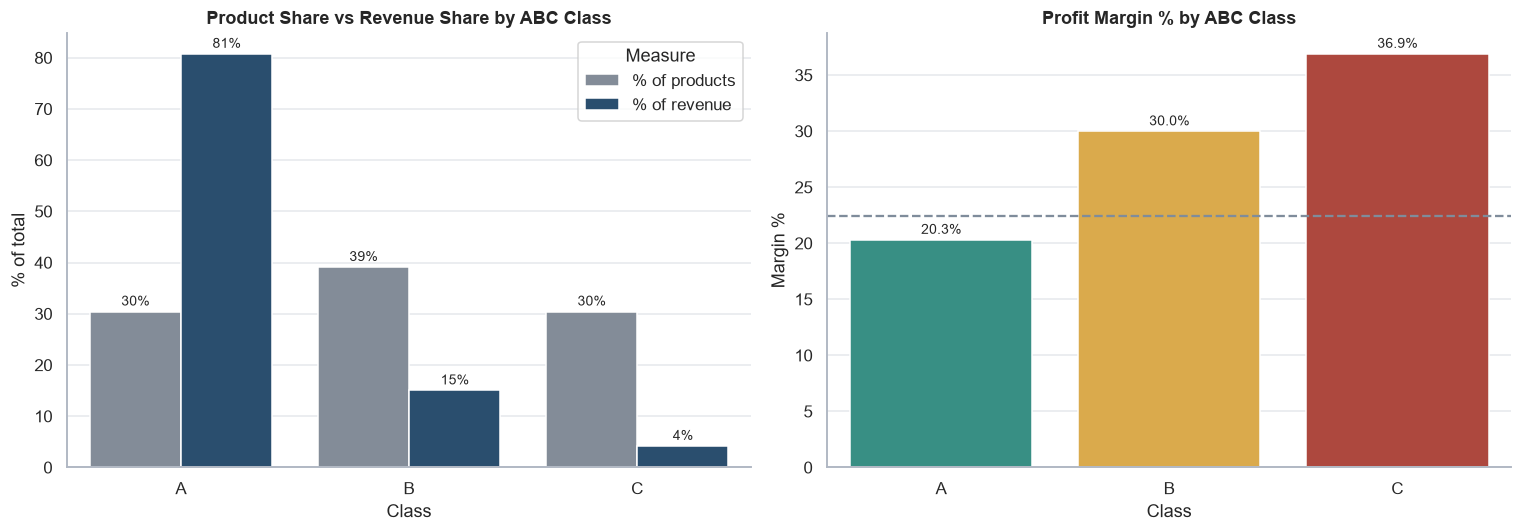

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sm = abc_summary(pa).reset_index()
t = sm.melt(id_vars="Class", value_vars=["Items_%", "Revenue_%"], var_name="Measure", value_name="Share_%")
t["Measure"] = t.Measure.map({"Items_%": "% of products", "Revenue_%": "% of revenue"})
sns.barplot(data=t, x="Class", y="Share_%", hue="Measure", palette=[C_GREY, C_BLUE], ax=ax[0]); label_bars(ax[0], "%.0f%%")
ax[0].set_title("Product Share vs Revenue Share by ABC Class"); ax[0].set_ylabel("% of total")

sns.barplot(data=sm, x="Class", y="Margin_%", palette=[C_TEAL, C_GOLD, C_RED], ax=ax[1]); label_bars(ax[1], "%.1f%%")
ax[1].axhline(OVERALL_MARGIN, ls="--", c=C_GREY); ax[1].set_title("Profit Margin % by ABC Class"); ax[1].set_ylabel("Margin %")
plt.tight_layout(); plt.show()

In [51]:
# Outlier & Anomaly Detection (KPI Trust Check)

In [52]:
# ---- EDA 10 | ANALYSIS (tables only) ----
an = (rec[rec.Anomaly != "OK"].groupby("Anomaly")
        .agg(Rows=("Order_ID","count"), Revenue=("Recognized_Revenue","sum"), Profit=("Recognized_Profit","sum")).reset_index())
print("Integrity anomalies and their impact:"); display(an.round(1))
display(rec[rec.Anomaly != "OK"].sort_values("Recognized_Profit")
          [["Order_ID","Order_Date","Product_Final","Quantity","Unit_Price","Discount_Pct","Recognized_Revenue","Recognized_Profit","Anomaly"]].round(2))

v = clean[clean.Recognized_Revenue > 0].copy()
lr = np.log1p(v.Recognized_Revenue); mad = np.median(np.abs(lr - lr.median()))
v["Mod_Z"] = 0.6745 * (lr - lr.median()) / mad
out = v[v.Mod_Z.abs() > 3.5]
print(f"Statistical outliers among valid lines: {len(out)} ({len(out)/len(v)*100:.1f}%), carrying {out.Recognized_Revenue.sum()/v.Recognized_Revenue.sum()*100:.1f}% of valid revenue")
display(out.sort_values("Recognized_Revenue", ascending=False)[["Order_ID","Product_Final","Sales_Channel","Quantity","Recognized_Revenue","Recognized_Profit","Mod_Z"]].round(2))
top1 = v.nlargest(max(1, int(len(v)*0.01)), "Recognized_Revenue").Recognized_Revenue.sum() / v.Recognized_Revenue.sum() * 100
big = v.loc[v.Recognized_Revenue.idxmax()]
print(f"Top 1% of lines = {top1:.1f}% of valid revenue. Largest single order ({big.Order_ID}, {big.Product_Final}, qty {big.Quantity:,.0f}) = {big.Recognized_Revenue/v.Recognized_Revenue.sum()*100:.1f}% of valid revenue -> verify with the source system.")

def kp(d):
    return pd.Series({"Revenue": d.Recognized_Revenue.sum(), "Profit": d.Recognized_Profit.sum(),
                      "Margin_%": d.Recognized_Profit.sum()/d.Recognized_Revenue.sum()*100,
                      "Orders": d.Order_ID.nunique(), "AOV": d.Recognized_Revenue.sum()/d.Order_ID.nunique()})
recon = pd.concat([kp(rec).rename("Reported"), kp(clean).rename("After integrity filter")], axis=1)
recon["Change_%"] = (recon["After integrity filter"]/recon["Reported"] - 1) * 100
print("Reported vs cleaned KPIs:"); display(recon.round(1))

mt = pd.concat([rec.groupby("Month").Recognized_Revenue.sum().rename("Reported revenue"),
                clean.groupby("Month").Recognized_Revenue.sum().rename("Clean revenue"),
                rec.groupby("Month").Recognized_Profit.sum().rename("Reported profit"),
                clean.groupby("Month").Recognized_Profit.sum().rename("Clean profit")], axis=1).fillna(0)
mt.index = mt.index.astype(str)

chg = recon.loc["Revenue", "Change_%"]
spike = (mt["Reported revenue"] - mt["Clean revenue"]).idxmax()
print(f"• Reported revenue is overstated by {abs(chg):.1f}% vs cleaned data; the largest distortion is in {spike}.")
findings.append(("10 Anomalies", f"{len(rec)-len(clean)} recognised rows fail integrity checks; revenue changes {chg:+.1f}% after removing them (largest distortion: {spike}).",
                 "Add entry validation (qty<1,000 without approval, price>0, customer ID mandatory); re-baseline KPIs before reporting."))

Integrity anomalies and their impact:


,Anomaly,Rows,Revenue,Profit
0,Non-positive quantity / price,3,10.80,-182.70
1,Placeholder quantity (9999),3,"29,032.30",535.20
2,Revenue ≠ Qty × Price,2,"22,147.70","20,712.50"


,Order_ID,Order_Date,Product_Final,Quantity,Unit_Price,Discount_Pct,Recognized_Revenue,Recognized_Profit,Anomaly
595,ORD10585,2024-04-17,Energy Drink 250Ml,"9,999.00",1.20,NaN,235.20,"-7,264.05",Placeholder quantity (9999)
377,ORD10179,2024-10-21,Toothpaste 150G,"1,200.00",1.90,NaN,92.06,"-1,287.94",Revenue ≠ Qty × Price
77,ORD10023,2024-10-23,Rice Noodles 200G,56.00,-2.50,0.02,-137.20,-177.52,Non-positive quantity / price
370,ORD10451,2024-08-18,Butter Cookies,2.00,-2.50,0.00,-5.00,-6.96,Non-positive quantity / price
334,ORD10455,2024-10-03,Basmati Rice 5Kg,24.00,-2.50,NaN,153.00,1.80,Non-positive quantity / price
154,ORD10466,2024-12-31,Salted Peanuts 200G,"9,999.00",1.60,0.15,"13,598.64","3,099.69",Placeholder quantity (9999)
369,ORD10025,2024-10-18,Salted Peanuts 200G,"9,999.00",1.60,0.05,"15,198.48","4,699.53",Placeholder quantity (9999)
264,ORD10307,2024-11-03,Toothpaste 150G,48.00,1.90,NaN,"22,055.62","22,000.42",Revenue ≠ Qty × Price


Statistical outliers among valid lines: 3 (0.7%), carrying 45.7% of valid revenue


,Order_ID,Product_Final,Sales_Channel,Quantity,Recognized_Revenue,Recognized_Profit,Mod_Z
442,ORD10598,Basmati Rice 5Kg,Modern Trade,"5,000.00","36,750.00","5,250.00",5.63
434,ORD10471,Choco Cream Biscuits,Online,"5,000.00","4,050.00","1,150.00",3.80
528,ORD10216,Basmati Rice 5Kg,Retail,500.00,"3,750.00",600.00,3.74


Top 1% of lines = 48.0% of valid revenue. Largest single order (ORD10598, Basmati Rice 5Kg, qty 5,000) = 37.7% of valid revenue -> verify with the source system.
Reported vs cleaned KPIs:


,Reported,After integrity filter,Change_%
Revenue,"148,602.30","97,411.50",-34.40
Profit,"42,941.10","21,876.10",-49.10
Margin_%,28.90,22.50,-22.30
Orders,444.00,437.00,-1.60
AOV,334.70,222.90,-33.40


• Reported revenue is overstated by 34.4% vs cleaned data; the largest distortion is in 2024-11.


In [53]:
# Monthly revenue and profit: reported vs clean

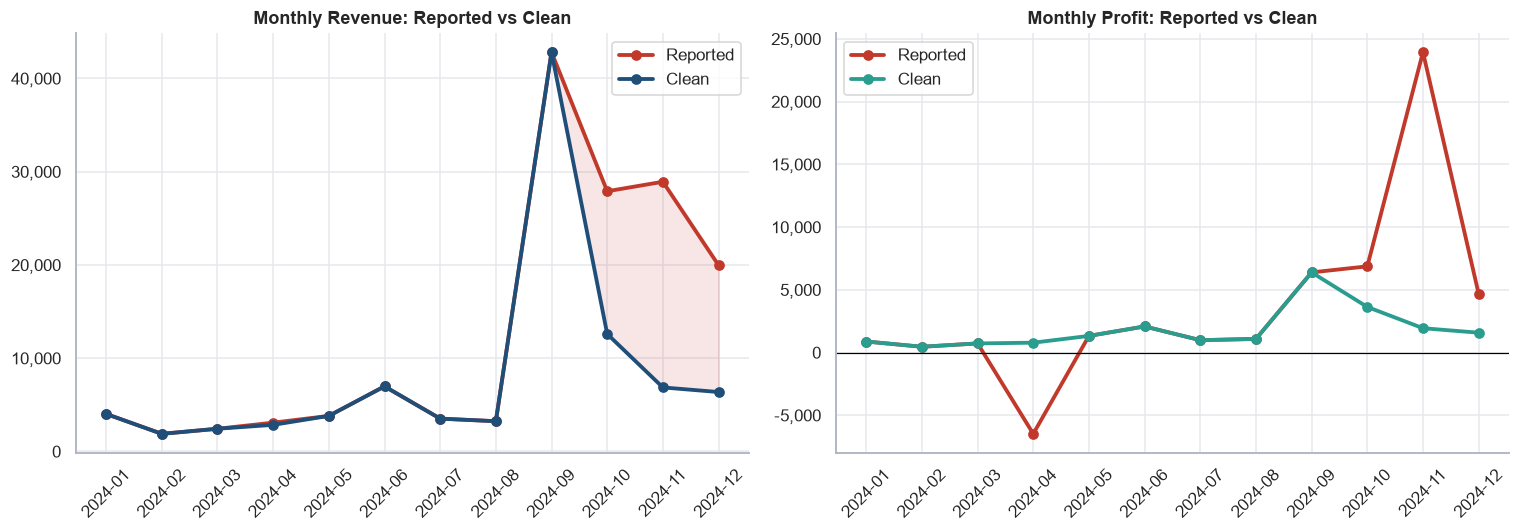

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(mt.index, mt["Reported revenue"], marker="o", lw=2.5, color=C_RED,  label="Reported")
ax[0].plot(mt.index, mt["Clean revenue"],    marker="o", lw=2.5, color=C_BLUE, label="Clean")
ax[0].fill_between(mt.index, mt["Clean revenue"], mt["Reported revenue"], color=C_RED, alpha=.12)
ax[0].set_title("Monthly Revenue: Reported vs Clean"); ax[0].yaxis.set_major_formatter(money); ax[0].legend()

ax[1].plot(mt.index, mt["Reported profit"], marker="o", lw=2.5, color=C_RED,  label="Reported")
ax[1].plot(mt.index, mt["Clean profit"],    marker="o", lw=2.5, color=C_TEAL, label="Clean")
ax[1].axhline(0, c="k", lw=.8); ax[1].set_title("Monthly Profit: Reported vs Clean"); ax[1].yaxis.set_major_formatter(money); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [55]:
# Distribution of order values (histogram) and revenue in flagged records (bar)

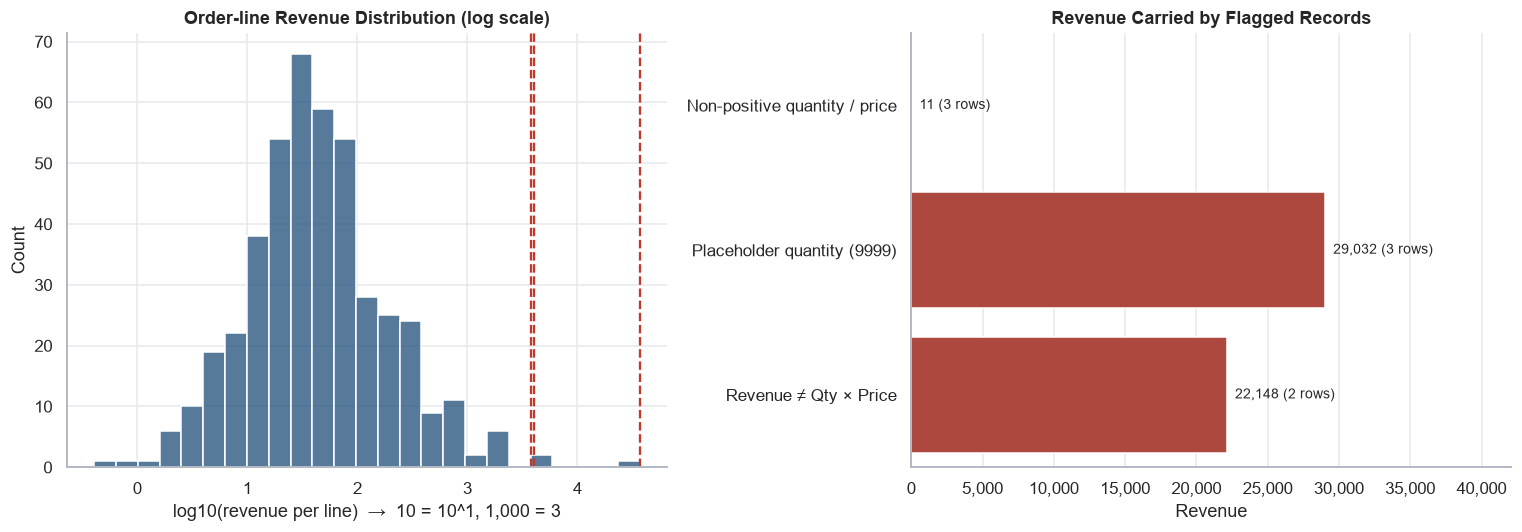

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(np.log10(v.Recognized_Revenue), bins=25, color=C_BLUE, ax=ax[0])
for val in np.log10(out.Recognized_Revenue): ax[0].axvline(val, color=C_RED, ls="--", lw=1.5)
ax[0].set_title("Order-line Revenue Distribution (log scale)"); ax[0].set_xlabel("log10(revenue per line)  →  10 = 10^1, 1,000 = 3")

sns.barplot(data=an, y="Anomaly", x="Revenue", color=C_RED, ax=ax[1])
for i, (r_, n_) in enumerate(zip(an.Revenue, an.Rows)): ax[1].text(r_, i, f"  {r_:,.0f} ({n_} rows)", va="center", fontsize=9)
ax[1].set_xlim(0, an.Revenue.max() * 1.45); ax[1].xaxis.set_major_formatter(money)
ax[1].set_title("Revenue Carried by Flagged Records"); ax[1].set_ylabel(""); ax[1].set_xlabel("Revenue")
plt.tight_layout(); plt.show()

In [57]:
summary = pd.DataFrame(findings, columns=["EDA", "Key finding", "Recommended business action"])
pd.set_option("display.max_colwidth", None)
display(summary.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

# Optional: export derived tables for Power BI / Excel
# with pd.ExcelWriter("FMCG_EDA_5_to_10_Outputs.xlsx") as xw:
#     for name, t in {"Channel": ch, "Discount_Band": band, "Category": cat, "Product_ABC": pa, "Customer_ABC": ca, "KPI_Recon": recon.reset_index(), "Summary": summary}.items():
#         t.to_excel(xw, sheet_name=name, index=False)

EDA,Key finding,Recommended business action
5 Channel,Modern Trade earns 16.9% margin vs Wholesale 32.2%.,Review pricing/terms in Modern Trade; prioritise growth in Wholesale.
6 Discount,Margin 28.3% → 18.3% from 0% to 15% discount; volume index 1.00 → 1.14; 2 below-cost lines.,Cap discounts where volume lift is weak; block below-cost net prices in order entry.
7 Profitability,Margins range 14.6% (Cooking Essentials) to 40.6% (Noodles); 2 loss-making lines.,Fix price/cost on thin-margin SKUs; shift promo spend to Star products; review 'Review / prune' SKUs.
8 Cancel/Return,"Cancellation 11.2% of orders (value 7,003); worst channel Online 15.9%, worst region South 13.4%.",Investigate stock-outs/fulfilment in the worst channel & region; add reason codes for cancellations and returns.
9 ABC/Pareto,7 of 23 products = 80% of revenue; top 20% customers = 75% of revenue; 7.6% of revenue has no customer ID.,Protect stock & margin of A-items; key-account plan for top customers; enforce customer ID at order entry.
10 Anomalies,8 recognised rows fail integrity checks; revenue changes -34.4% after removing them (largest distortion: 2024-11).,"Add entry validation (qty<1,000 without approval, price>0, customer ID mandatory); re-baseline KPIs before reporting."


In [58]:

# ============================================================
# FINAL STEP: EXPORT FMCG ANALYSIS RESULTS FOR POWER BI
# ============================================================

import pandas as pd
import numpy as np

# 1. Create a collection of existing analysis tables

powerbi_tables = {
    "Fact_Sales": df,
    "Recognized_Sales": clean,
    "Data_Quality": rec,
    "Category_Analysis": cat,
    "Brand_Analysis": brand,
    "Product_Analysis": prod,
    "Order_Status": status,
    "Product_ABC": pa,
    "Customer_ABC": ca,
    "Anomaly_Analysis": an,
    "Outlier_Analysis": out,
    "Executive_Summary": summary
}

# 2. Add additional monthly analysis

if "Order_Date" in df.columns:
    monthly_sales = df.copy()

    monthly_sales["Order_Date"] = pd.to_datetime(
        monthly_sales["Order_Date"], errors="coerce"
    )

    monthly_sales["Year_Month"] = (
        monthly_sales["Order_Date"].dt.to_period("M").astype("string")
    )

    monthly_kpi = monthly_sales.groupby("Year_Month").agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Sales=("Sales_Amount_Final", "sum")
    ).reset_index()

    powerbi_tables["Monthly_Analysis"] = monthly_kpi

# 3. Create an overall KPI summary

total_revenue = clean["Recognized_Revenue"].sum()
total_cost = clean["Recognized_Cost"].sum()
total_profit = clean["Recognized_Profit"].sum()

total_orders = clean["Order_ID"].nunique()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Profit Margin %",
        "Total Orders",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_profit,
        (total_profit / total_revenue * 100)
            if total_revenue else 0,
        total_orders,
        (total_revenue / total_orders)
            if total_orders else 0
    ]
})

powerbi_tables["KPI_Summary"] = kpi_summary

# 4. Export all tables into one Excel workbook

file_name = "FMCG_PowerBI_Dashboard_Data.xlsx"

with pd.ExcelWriter(file_name, engine="openpyxl") as writer:

    for sheet_name, table in powerbi_tables.items():

        # Export only available DataFrames
        if isinstance(table, pd.DataFrame):

            export_table = table.copy()

            # Remove unnecessary index
            export_table = export_table.reset_index(drop=True)

            # Make column names Excel-friendly
            if isinstance(export_table.columns, pd.MultiIndex):
                export_table.columns = [
                    "_".join(str(x) for x in col if str(x) != "")
                    for col in export_table.columns
                ]

            export_table.to_excel(
                writer,
                sheet_name=sheet_name[:31],
                index=False
            )

            # Format Excel columns
            worksheet = writer.sheets[sheet_name[:31]]
            worksheet.freeze_panes = "A2"
            worksheet.auto_filter.ref = worksheet.dimensions

            for column in worksheet.columns:
                max_length = max(
                    len(str(cell.value)) if cell.value is not None else 0
                    for cell in column
                )
                worksheet.column_dimensions[
                    column[0].column_letter
                ].width = min(max_length + 3, 35)

print("Excel workbook successfully created!")
print("File name:", file_name)
print("Total sheets:", len(powerbi_tables))
print("Exported sheets:")

for sheet in powerbi_tables:
    print("-", sheet)


Excel workbook successfully created!
File name: FMCG_PowerBI_Dashboard_Data.xlsx
Total sheets: 14
Exported sheets:
- Fact_Sales
- Recognized_Sales
- Data_Quality
- Category_Analysis
- Brand_Analysis
- Product_Analysis
- Order_Status
- Product_ABC
- Customer_ABC
- Anomaly_Analysis
- Outlier_Analysis
- Executive_Summary
- Monthly_Analysis
- KPI_Summary


In [59]:
"Discount_Analysis": band,
"KPI_Reconciliation": recon.reset_index(),
"Monthly_Clean_vs_Reported": mt.reset_index()

SyntaxError: illegal target for annotation (2333153198.py, line 1)